# Retrieval-Augmented Generation (RAG)

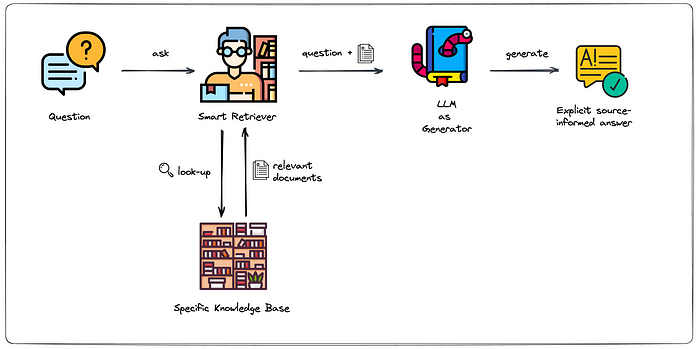

## Instalacje i importy

In [1]:
!pip install -q sentence-transformers faiss-cpu transformers

In [2]:
import os
import torch
import faiss
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer
from transformers import pipeline, set_seed

W1115 23:00:59.318000 90622 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Pobranie dokumentów

In [3]:
def load_documents(doc_dir: str) -> list:
    print("Loading documents...")

    def chunk_text(text: str, chunk_size: int = 50, overlap: int = 10) -> list:
        # Dokuemnty potrafią być olbrzymie
        # Będziemy je dzielić na fragmenty - chunki
        # Chcemy nakładać fragmenty, tak żeby zaachować spójność pomiędzy fragmentami,
        # które są powiązane
        words = text.split()
        chunks = []
        for i in range(0, len(words), chunk_size - overlap):
            chunks.append(" ".join(words[i:i + chunk_size]))
        return chunks


    docs = []
    # Pobierz dokumenty i pochunkuj zawartość
    for file in Path(doc_dir).glob("*.txt"):
        text = file.read_text(encoding="utf-8")
        docs.extend(chunk_text(text))

    print(f"Loaded: Number of docs: {len(docs)}")
    return docs

## Embeddingi

In [4]:
def embed_documents(docs: list, model_name: str = "all-MiniLM-L6-v2") -> tuple:
    print("Embedding documents...")
    # Zwróć model i zembedingowane kawałki dokumentów
    model = SentenceTransformer(model_name)
    embeddings = model.encode(docs, convert_to_numpy=True)
    return embeddings, model

## FAISS index

FAISS index to struktura danych do szybkiego wyszukiwania najbliższych wektorów

In [5]:
def build_faiss_index(embeddings: np.ndarray) -> faiss.IndexFlatL2:
    print("Building FAISS index...")
    # Jeśli tutaj się wysypujemy to znaczy że coś wyżej poszło nie tak
    if embeddings.ndim != 2 or embeddings.shape[0] == 0:
        raise ValueError(
            f"Embeddings must be a non‑empty 2‑D array. Received shape: {embeddings.shape}"
        )
    # Jeśli nasze mebedingi mają rozmiar (1000, 512) to znaczy że mamy 1000 fragmentów tekstu każdy to wektor o długości 512
    dim = embeddings.shape[1]
    # Tworzymy obiekt Indexu FAISS
    index = faiss.IndexFlatL2(dim)
    # Dodajemy nasze gotowe embeddingi do indexu
    index.add(embeddings)
    return index

## Retrieval - wyciągnij najważniejszy fragment

In [6]:
def retrieve(index: faiss.IndexFlatL2, query_embedding: np.ndarray, k: int = 3) -> tuple:
    print(f"Retrieving top-{k} documents...")
    # znajdź w indexie ineksy najbardziej podobnych wektorów w bazie do naszego zapytania
    # zwróć również odległości tych indeksów
    distances, indices = index.search(query_embedding, k)
    return indices[0], distances[0]

## Gotowy prompt

In [7]:
def build_prompt(context_docs: list, user_query: str) -> str:
    print("Building prompt...")
    # Zbuduj prompt który przekażemy generatorowi
    # Prompt powinien mieć kontekst, czyli dokumenty zwrócone przez retrievier
    # model do generacji nie widział wszystkich dokumentów, więc trzeba mu to podać!
    # dodatkowo pytanie i zachęte dla modelu do odpowiedzi (np ".... Answer:")
    context = "\n".join(context_docs)
    prompt = f"Context:\n{context}\n\nQuestion: {user_query}\nAnswer:"
    return prompt


## Odpowiedź

In [8]:
def generate_answer(
    prompt: str,
    model_name: str = "gpt2-large",
    max_new_tokens: int = 50,
    dtype: torch.dtype = None,
) -> str:
    # użyjmy pipline'a z wybranym modelem do zadania "text-generation"
    generator = pipeline("text-generation", model=model_name, dtype=dtype)

    set_seed(42)
    if generator.model.config.pad_token_id is None:
        generator.model.config.pad_token_id = generator.model.config.eos_token_id

    # generujemy odpowiedź modelu poprzez użycie pipeline'a
    # Następnie zwracamy odpowiedź - podczas budowania prompta zostawiliśmy miejsce modelowi
    # do odpowiedzi "Answer" - zwróćmy wszystko co zostanie wygenerowane po tym słowie
    output = generator(
        prompt,
        max_new_tokens=max_new_tokens,
        num_return_sequences=1,
        do_sample=False,  # deterministic
    )[0]["generated_text"]

    answer = output.split("Answer:")[-1].strip()
    return answer

## Test - wyciągnij odpowiedź na podstawie dokumentów

In [12]:
docs = load_documents("docs")  # wrzuć pliki .txt do `docs/`

embeddings, embed_model = embed_documents(docs)

faiss_index = build_faiss_index(embeddings)

user_query = "What is the probability of rolling a 6 on a die?" # Zaktualizuj prompt odpowiadający Twoim dokuemntom
query_vec = embed_model.encode([user_query], convert_to_numpy=True)

top_k_indices, _ = retrieve(faiss_index, query_vec, k=3)
retrieved_docs = [docs[i] for i in top_k_indices]

prompt = build_prompt(retrieved_docs, user_query)

answer = generate_answer(
    prompt,
    max_new_tokens=5,          # dla dłuższych odpowiedzi, zwiększ
    dtype=torch.float16,
)

print(f"\n- Prompt:\n{prompt}\n\n")
print(f"\n- Question:\n{user_query}\n\n")
print(f"\n- Answer:\n{answer}\n\n")


Loading documents...
Loaded: Number of docs: 16
Embedding documents...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Building FAISS index...
Retrieving top-3 documents...
Building prompt...


Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]


- Prompt:
Context:
is certain. When all outcomes are equally likely, the probability of an event is the number of favourable outcomes divided by the number of all possible outcomes. For example, the probability of rolling a 6 on a fair die is 1/6, and the probability of getting heads when tossing a
1/6, and the probability of getting heads when tossing a coin is 1/2. Two events are independent if the result of one does not affect the other. For independent events, the probability that both happen is the product of their probabilities, so the probability of getting two heads in a
probabilities, so the probability of getting two heads in a row is 1/2 * 1/2 = 1/4.

Question: What is the probability of rolling a 6 on a die?
Answer:



- Question:
What is the probability of rolling a 6 on a die?



- Answer:
1/6


